# **[실습 3-1] Decision Tree**

##**데이터셋 설명**

| 컬럼명 | 설명 |
|---|---|
| animal_id | 동물 고유 ID |
| body_length_cm | 몸 길이 (cm) |
| weight_kg | 몸무게 (kg) |
| body_size_score | 몸 크기 종합 점수 (몸길이·몸무게 기반 파생 지표) |
| num_legs | 다리 개수 |
| has_fur | 털 보유 여부 (1: 있음, 0: 없음) |
| has_feathers | 깃털 보유 여부 (1: 있음, 0: 없음) |
| has_scales | 비늘 보유 여부 (1: 있음, 0: 없음) |
| lays_eggs | 알을 낳는지 여부 (1: 예, 0: 아니오) |
| is_warm_blooded | 온혈동물 여부 (1: 온혈, 0: 냉혈) |
| lives_in_water | 주로 물에서 서식하는지 여부 (1: 예, 0: 아니오) |
| can_fly | 비행 가능 여부 (1: 예, 0: 아니오) |
| lifespan_years | 평균 수명 (년) |
| top_speed_kmh | 최고 속도 (km/h) |
| habitat | 주요 서식지 (범주형: Forest, Ocean, Grassland, Desert, Wetland, Arctic, Mountain) |
| diet_type | 식성 (범주형: Carnivore, Herbivore, Omnivore) |
| **animal_class** | **(타겟) 동물의 강 - Mammal / Bird / Reptile / Fish / Amphibian** |

## **데이터셋 URL**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/animals.csv

## **1. 데이터 살펴보기**

데이터를 분석하여 인사이트를 찾아내는 과정입니다.
- 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.
- 그리고 데이터를 이해하기 위한 여러 정보들을 찾아 csv 형태로 추출하여 채점 사이트에 제출합니다.

**colab에서 csv 파일 다운로드하기**
```
from google.colab import files
files.download("submission.csv")
```

**Q1. 데이터를 불러오고 상위 5개 행을 확인하세요.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/animals.csv")
df.head()

,animal_name,body_length_cm,weight_kg,body_size_score,num_legs,has_fur,has_feathers,has_scales,lays_eggs,is_warm_blooded,lives_in_water,can_fly,lifespan_years,top_speed_kmh,habitat,diet_type,animal_class
0,Lion,260,190.0,348.0,4,1,0,0,0,1,0,0,14.0,80.0,Grassland,Carnivore,Mammal
1,Moose,250,400.0,465.0,4,1,0,0,0,1,0,0,15.0,56.0,Forest,Herbivore,Mammal
2,Gray Wolf,150,40.0,159.0,4,1,0,0,0,1,0,0,8.0,50.0,Forest,Carnivore,Mammal
3,Red Fox,100,5.5,93.3,4,1,0,0,0,1,0,0,4.0,50.0,Forest,Omnivore,Mammal
4,Domestic Cat,46,4.5,44.1,4,1,0,0,0,1,0,0,15.0,48.0,Grassland,Carnivore,Mammal


**Q2. 데이터의 전체적인 구조를 확인하세요.**

In [3]:
# code here
df.shape

(100, 17)

**Q3. 수치형 컬럼들의 기초 통계량을 확인하세요.**

In [4]:
# code here
df.describe()

,body_length_cm,weight_kg,body_size_score,num_legs,has_fur,has_feathers,has_scales,lays_eggs,is_warm_blooded,lives_in_water,can_fly,lifespan_years,top_speed_kmh
count,100.000000,100.000000,100.000000,100.00000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,99.410000,70.174980,131.574100,2.52000,0.180000,0.200000,0.340000,0.720000,0.400000,0.440000,0.180000,18.925000,30.727200
std,104.929326,163.052134,177.772956,1.69658,0.386123,0.402015,0.476095,0.451261,0.492366,0.498888,0.386123,16.621055,43.300501
min,3.000000,0.001000,2.700000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.500000,0.020000
25%,20.000000,0.165000,18.035000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,3.000000
50%,60.000000,2.500000,54.450000,4.00000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,15.000000,16.000000
75%,150.000000,40.000000,172.500000,4.00000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,21.250000,48.500000
max,470.000000,1000.000000,1023.000000,4.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,100.000000,320.000000


## **2. 데이터 분석하기**

### **2-1. 데이터 탐색하기**

**Q1. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- 서식지별 동물들의 수를 찾아 주세요.

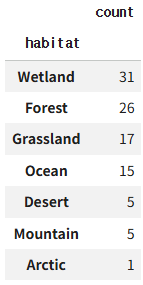

In [14]:
# code here
df["habitat"].value_counts().to_csv("animal01.csv")


**Q2. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- 온혈동물 중 각 타겟 클래스에 분포되어있는 동물의 수를 찾아 주세요.

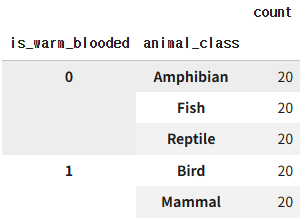

In [16]:
# code here
df.groupby("is_warm_blooded")["animal_class"].value_counts().to_csv("animal02.csv")

**Q3. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- 육식동물 중 몸 길이 (body_length_cm)이 가장 긴 5마리의 동물의 이름을 큰 순서대로 저장합니다.

컬럼명은 "animal_name"으로 5마리의 동물명을 저장하여 제출합니다.

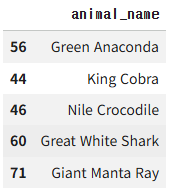

In [61]:
# code here
df03 = df[df["diet_type"] == "Carnivore"]
df03.sort_values("body_length_cm",ascending=False).head(5)["animal_name"].to_csv("animal03.csv", index=False)
# df_new.sort_values("body_length_cm",ascending=False).head(5)["animal_name"].to_csv("animal03.csv")

**Q4. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- 날 수 있으면서 동시에 온혈 동물인 동물들의 비율을 animal_class별로 소수점 2자리까지 구해주세요.

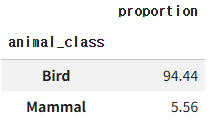

In [ ]:
# code here
df_new = df[(df["can_fly"] == 1) & (df["is_warm_blooded"] == 1)]
(df_new["animal_class"].value_counts(normalize=True) * 100).round(2).to_csv("animal04.csv")

**Q5. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- 수명이 상위 10%에 해당하는 동물들을 찾아보세요.
- 그리고 이 동물들을 animal_class별 비율을 소수점 2자리까지 구해주세요.

In [60]:
# code here
df05 = df[(df["lifespan_years"] >= df["lifespan_years"].quantile(0.9))]
(df05["animal_class"].value_counts(normalize=True) * 100).round(2).to_csv("animal05.csv")

### **2-2. 데이터 시각화하기**

**Q1. 서식지(habitat)별 동물들의 수를 막대 그래프로 그려 주세요.**
- animal_class 별 서식지도 같이 볼 수 있도록 해 주세요.

그리고 이 그래프에서 알 수 있게 된 정보를 코드 아래에 적어 주세요.

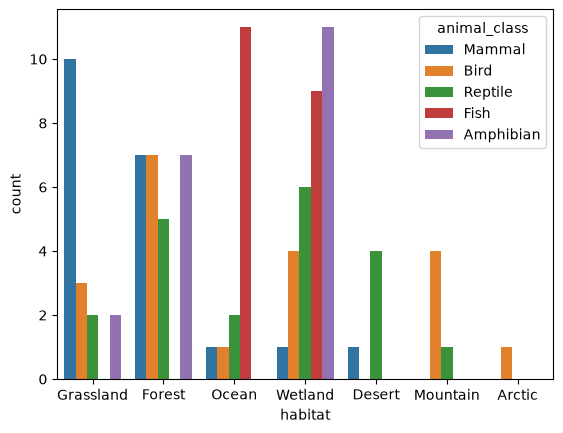

In [75]:
# code here

sns.countplot(df, x = "habitat", hue = "animal_class")
plt.show()

**Q2. animal_class별 몸무게 분포를 boxplot으로 시각화하여 이상치를 확인하세요.**

그리고 이 그래프에서 알 수 있게 된 정보를 코드 아래에 적어 주세요.

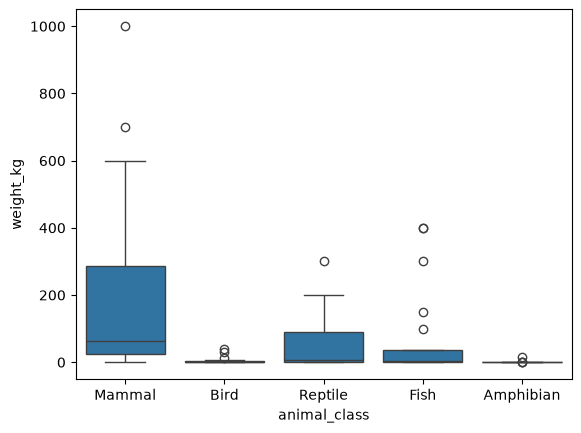

In [77]:
# code here

sns.boxplot(df, x = "animal_class", y = "weight_kg")
plt.show()

**Q3. body_size_score와 weight_kg의 관계를 scatter plot으로 시각화하세요.**
- animal_class 별로 색을 다르게 표현해주세요.

그리고 이 그래프에서 알 수 있게 된 정보를 코드 아래에 적어 주세요.

<Axes: xlabel='body_size_score', ylabel='weight_kg'>

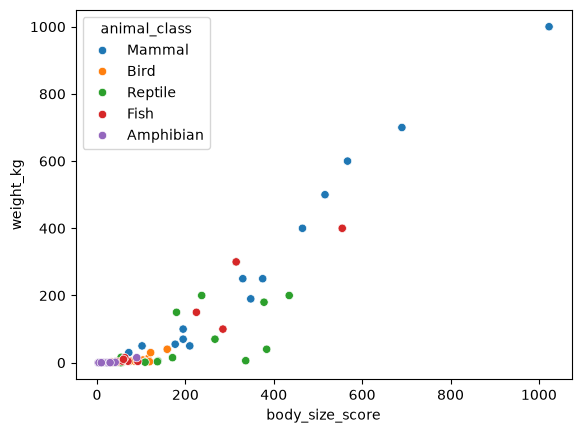

In [85]:
# code here
sns.scatterplot(df, x = "body_size_score", y = "weight_kg", hue = "animal_class")

## **3. 데이터 전처리하기**

In [80]:
# 전처리하다 데이터가 망가지면 여기서부터 재시작!
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/animals.csv")
df.head()

,animal_name,body_length_cm,weight_kg,body_size_score,num_legs,has_fur,has_feathers,has_scales,lays_eggs,is_warm_blooded,lives_in_water,can_fly,lifespan_years,top_speed_kmh,habitat,diet_type,animal_class
0,Lion,260,190.0,348.0,4,1,0,0,0,1,0,0,14.0,80.0,Grassland,Carnivore,Mammal
1,Moose,250,400.0,465.0,4,1,0,0,0,1,0,0,15.0,56.0,Forest,Herbivore,Mammal
2,Gray Wolf,150,40.0,159.0,4,1,0,0,0,1,0,0,8.0,50.0,Forest,Carnivore,Mammal
3,Red Fox,100,5.5,93.3,4,1,0,0,0,1,0,0,4.0,50.0,Forest,Omnivore,Mammal
4,Domestic Cat,46,4.5,44.1,4,1,0,0,0,1,0,0,15.0,48.0,Grassland,Carnivore,Mammal


### **3-1. 데이터 분리하기**

**Q1. animal_class를 타겟으로 하여 학습용(train)과 테스트용(test) 데이터로 분리하세요.**
- 비율: 7(학습) : 3(테스트)
- random_state = 101


이번 문항은 클래스가 여러개이며, 데이터의 개수가 충분하지 않은 편이다.
- 학습-테스트 데이터를 불균형하게나누면, 특정 class는 절대로 예측하지 못하는 모델이 생성될 수 있다.
- 최대한 클래스의 비율을 유지하면서 데이터를 나눌수 있도록, "stratify"옵션을 활용한다.

```
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101, stratify=y)
```

In [88]:
# code here
X = df.drop("animal_class", axis = 1)
y = df["animal_class"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101, stratify=y)

In [89]:
X_train["habitat"].value_counts()

habitat
Wetland      18
Forest       17
Ocean        14
Grassland    13
Mountain      4
Desert        4
Name: count, dtype: int64

In [90]:
X_test["habitat"].value_counts()

habitat
Wetland      13
Forest        9
Grassland     4
Mountain      1
Arctic        1
Ocean         1
Desert        1
Name: count, dtype: int64

### **3-2. 결측치 처리하기**

이번 데이터는 결측치가 존재하지 않는다.

### **3-3. 이상치 처리하기**

이번 데이터에는 이상치가 존재하지 않는다.
- 이상치라고 IQR로 판단되더라도, 실제 동물의 정보일 뿐이다.

### **3-4. 범주형 변수 인코딩**

**Q1. 범주형 변수(habitat, diet_type)를 One-Hot 인코딩하세요.**
- "Arctic" habitat에 사는 동물은 하나밖에 없습니다. (어떻게 보면 이상치 또는 데이터 부실)

OneHotEncoder에서 handle_unknown옵션을 "ignore"로 설정해 주세요.

```
ohe = OneHotEncoder(sparse_output=False, drop="first", handle_unknown="ignore")
```


In [91]:
# code here
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False, drop="first", handle_unknown="ignore")

# 인코딩 해야 하는 열은 2개
cols = ["habitat", "diet_type"]

In [ ]:
X_train_encoded = pd.DataFrame(ohe.fit_transform(X_train[cols]), 
                               columns= ohe.get_feature_names_out(),
                               index = X_train.index)

In [ ]:
X_test_encoded = pd.DataFrame(ohe.transform(X_test[cols]), 
                              columns= ohe.get_feature_names_out(),
                               index = X_test.index)

c:\Users\user\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [99]:
X_train_encoded.head()

,habitat_Forest,habitat_Grassland,habitat_Mountain,habitat_Ocean,habitat_Wetland,diet_type_Herbivore,diet_type_Omnivore
24,0.0,0.0,1.0,0.0,0.0,0.0,0.0
47,0.0,1.0,0.0,0.0,0.0,1.0,0.0
92,0.0,0.0,0.0,0.0,1.0,0.0,0.0
68,0.0,0.0,0.0,0.0,1.0,0.0,1.0
59,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [100]:
X_test_encoded.head()

,habitat_Forest,habitat_Grassland,habitat_Mountain,habitat_Ocean,habitat_Wetland,diet_type_Herbivore,diet_type_Omnivore
55,0.0,0.0,0.0,0.0,1.0,0.0,0.0
54,1.0,0.0,0.0,0.0,0.0,0.0,1.0
86,1.0,0.0,0.0,0.0,0.0,0.0,0.0
66,0.0,0.0,0.0,0.0,1.0,0.0,1.0
91,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [101]:
X_train_encoded = pd.concat([X_train.drop(cols, axis=1), X_train_encoded], axis = 1)

In [102]:
X_test_encoded = pd.concat([X_test.drop(cols, axis=1), X_test_encoded], axis = 1)

In [ ]:
#이름은 필요 없으니까 두쪽에서 다 이름 열은 삭제
X_train_encoded = X_train_encoded.drop("animal_name", axis = 1)

In [105]:
X_test_encoded = X_test_encoded.drop("animal_name", axis = 1)

## **4. 모델링**

### **4-1. 모델 학습**

**Q1. 결정 트리 모델을 생성하세요.**

- criterion = "entropy", max_depth=2, min_samples_leaf=3 로 설정해 봅시다.


In [ ]:
# code here
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    criterion="entropy", 
    max_depth=2,            
    min_samples_leaf=3      # 마지막 노드에 최소 3개
)


**Q2. 모델을 전처리된 데이터로 학습시켜 주세요.**

In [109]:
# code here
model.fit(X_train_encoded, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

### **4-2. 모델 예측**

**Q1. 예측 결과를 y_pred에 저장합니다.**

In [110]:
# code here
y_pred = model.predict(X_test_encoded)

### **4-3. 모델 평가**

**Q1.정확도, classification report, confusion matrix로 모델의 성능을 평가합니다.**

In [111]:
# code here
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print(f"accuracy : {accuracy_score(y_test, y_pred)}")

accuracy : 0.8


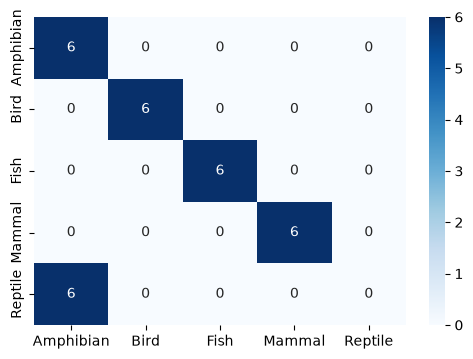

In [121]:
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred), cmap = "Blues", annot=True, 
            xticklabels=model.classes_,
            yticklabels=model.classes_,
            )

plt.show()

### **4-4. 트리 구조 시각화**

**Q1. plot_tree를 이용해 학습된 의사결정나무의 구조를 시각화하세요.**

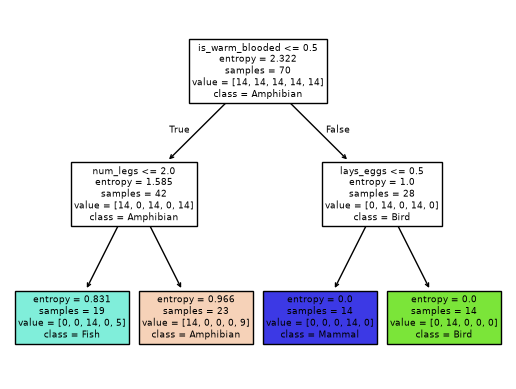

In [120]:
# code here
from sklearn.tree import plot_tree
#plot_tree(모델, feature_names=(특징은 어떤게 있었는지))
plot_tree(model, feature_names=X_train_encoded.columns, class_names=model.classes_, filled=True)
plt.show()

### **4-5. 피처 중요도(Feature Importance) 확인**

**Q1. 학습된 모델의 어떤 피처가 분류에 가장 중요했는지 시각화하세요.**
- 모델의 feature_importances_를 활용해 주세요.

In [ ]:
# code here
feature_importances = pd.Series(model.feature_importances_, index = X_train_encoded.columns)
feature_importances = feature_importances.sort_values(ascending=False)

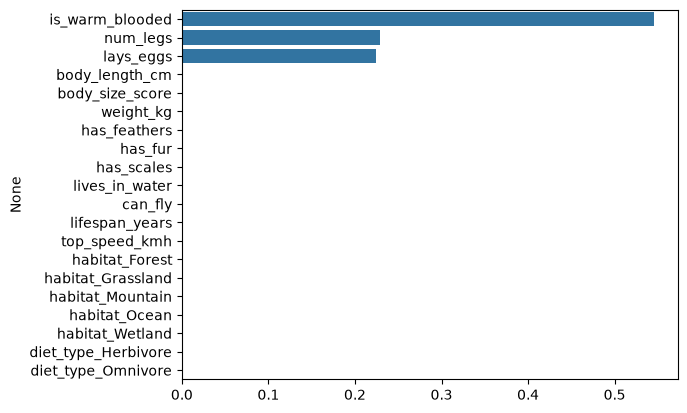

In [126]:
sns.barplot(x = feature_importances.values, y = feature_importances.index)
plt.show()

# **[실습 3-2] Cross Validation**

## **5. Cross Validation**

### **5-1. GridSearch CV**

**Q1. GridSearch CV를 통해 최적의 하이퍼파라미터를 찾아보세요 .**

param_grid는 다음과 같이 설정합니다.
- max_depth : 3, 5, 7, 10
- min_samples_split : 2, 5, 10,
- criterion : "gini", "entropy"

In [ ]:
# code here
from sklearn.model_selection import GridSearchCV

param_grid = {
    # hyperparameter = {~~~~ 옵션} -> 딕셔너리의 형태
    "max_depth": [3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "criterion": ["gini", "entropy"]
}

In [187]:
grid_search = GridSearchCV(
    # 1. estimator = model
    estimator= DecisionTreeClassifier(),
    # 2. search space
    param_grid= param_grid,
    # 3. cros validation에 대한 옵션(default는 stratified k-fold가 적용)
    cv = 10,
    # 4. verbose: 학습 현항을 어떻게 표기할거냐?
    verbose=1  # 폴드/조합 개수만
)

In [188]:
grid_search.fit(X_train_encoded, y_train)

Fitting 10 folds for each of 24 candidates, totalling 240 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, ...], 'min_samples_split': [2, 5, ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_sea

**Q2. Grid Search로 찾은 최고 점수를 출력합니다.**
- Default 성능 평가 점수는 "accuracy" 입니다.

```
grid_search.best_score_
```

In [189]:
# code here
# 평균값
print(grid_search.best_score_)

0.9428571428571428


**Q3. Grid Search로 찾은 최상의 hyperparameter를 출력합니다.**

```
grid_search.best_params_
```

In [190]:
# code here
print(grid_search.best_params_)

{'criterion': 'entropy', 'max_depth': 3, 'min_samples_split': 5}


**Q4. Grid Search로 생성된 최상의 하이퍼파라미터를 탑재한 모델을 출력합니다.**

```
grid_search.best_estimator_
```

In [191]:
# code here
model = grid_search.best_estimator_

In [192]:
model

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

### **5-2. 모델 예측**

**Q1. 최상의 하이퍼파라미터가 탑재된 모델을 활용해서 X_test에 대한 예측 결과를 냅니다.**

In [ ]:
# code here

### **5-3. 모델 평가**

**Q1.정확도, classification report, confusion matrix로 모델의 성능을 평가합니다.**

In [193]:
# code here# code here
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print(f"accuracy : {accuracy_score(y_test, y_pred)}")

accuracy : 0.8


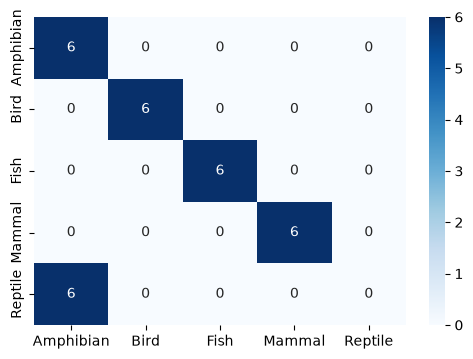

In [194]:
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred), cmap = "Blues", annot=True, 
            xticklabels=model.classes_,
            yticklabels=model.classes_,
            )

plt.show()

### **5-4. 트리 구조 시각화**

**Q1. plot_tree를 이용해 학습된 의사결정나무의 구조를 시각화하세요.**

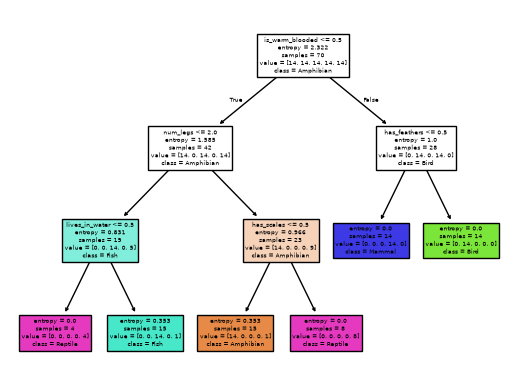

In [157]:
# code here
from sklearn.tree import plot_tree
#plot_tree(모델, feature_names=(특징은 어떤게 있었는지))
plot_tree(model, feature_names=X_train_encoded.columns, class_names=model.classes_, filled=True)
plt.show()

### **5-5. 피처 중요도(Feature Importance) 확인**

**Q1. 학습된 모델의 어떤 피처가 분류에 가장 중요했는지 시각화하세요.**

- 모델의 feature_importances_를 활용해 주세요.

In [155]:
# code here
feature_importances = pd.Series(model.feature_importances_, index = X_train_encoded.columns)
feature_importances = feature_importances.sort_values(ascending=False)

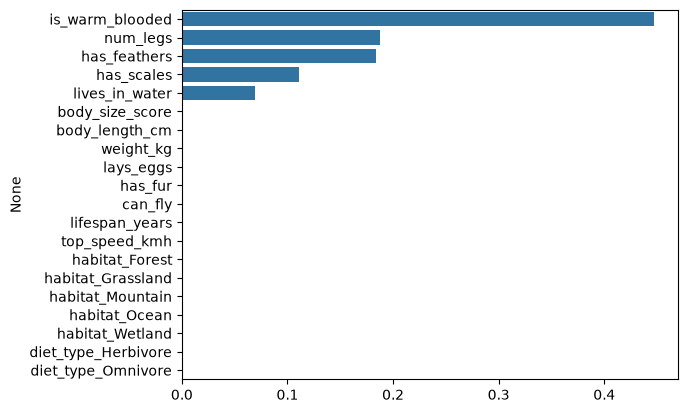

In [156]:
sns.barplot(x = feature_importances.values, y = feature_importances.index)
plt.show()

## **6. 채점하기**

데이터 전처리 방법과 학습된 모델을 활용하여 미공개 데이터에 대한 분류 예측 결과를 "animal_class" 컬럼에 순서대로 저장하고, 제출합니다.

**미공개 데이터 URL:**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/animals_submission.csv

In [179]:
submission = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/animals_submission.csv")
submission.head()

,animal_name,body_length_cm,weight_kg,body_size_score,num_legs,has_fur,has_feathers,has_scales,lays_eggs,is_warm_blooded,lives_in_water,can_fly,lifespan_years,top_speed_kmh,habitat,diet_type
0,Polar Bear,250,450.0,495.0,4,1,0,0,0,1,0,0,25,40.0,Arctic,Carnivore
1,Snow Leopard,115,45.0,130.5,4,1,0,0,0,1,0,0,15,55.0,Mountain,Carnivore
2,Orca,700,5000.0,3630.0,0,0,0,0,0,1,1,0,50,54.0,Ocean,Carnivore
3,Platypus,45,1.5,41.4,4,1,0,0,1,1,1,0,11,6.0,Wetland,Carnivore
4,European Hedgehog,25,1.0,23.1,4,0,0,0,0,1,0,0,5,6.0,Grassland,Omnivore


In [180]:
# code here

submission = submission.drop("animal_name", axis = 1)
submission

,body_length_cm,weight_kg,body_size_score,num_legs,has_fur,has_feathers,has_scales,lays_eggs,is_warm_blooded,lives_in_water,can_fly,lifespan_years,top_speed_kmh,habitat,diet_type
0,250,450.000,495.00,4,1,0,0,0,1,0,0,25,40.00,Arctic,Carnivore
1,115,45.000,130.50,4,1,0,0,0,1,0,0,15,55.00,Mountain,Carnivore
2,700,5000.000,3630.00,0,0,0,0,0,1,1,0,50,54.00,Ocean,Carnivore
3,45,1.500,41.40,4,1,0,0,1,1,1,0,11,6.00,Wetland,Carnivore
4,25,1.000,23.10,4,0,0,0,0,1,0,0,5,6.00,Grassland,Omnivore
5,60,4.000,56.40,4,1,0,0,0,1,0,0,20,0.24,Forest,Herbivore
6,60,2.000,55.20,2,0,1,0,1,1,0,1,10,80.00,Arctic,Carnivore
7,55,0.300,49.68,2,0,1,0,1,1,0,0,8,32.00,Desert,Carnivore
8,115,9.000,108.90,2,0,1,0,1,1,0,1,50,80.00,Ocean,Carnivore
9,17,0.030,15.32,2,0,1,0,1,1,0,1,2,26.00,Forest,Carnivore


In [181]:
sub_cols = ["habitat", "diet_type"]

submission_encoded = pd.DataFrame(ohe.transform(submission[sub_cols]),
                                  columns = ohe.get_feature_names_out(),
                                  index = submission.index)

submission_encoded.head()

c:\Users\user\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,habitat_Forest,habitat_Grassland,habitat_Mountain,habitat_Ocean,habitat_Wetland,diet_type_Herbivore,diet_type_Omnivore
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [182]:
submission_encoded = pd.concat([submission.drop(sub_cols, axis=1), submission_encoded], axis = 1)
submission_encoded

,body_length_cm,weight_kg,body_size_score,num_legs,has_fur,has_feathers,has_scales,lays_eggs,is_warm_blooded,lives_in_water,can_fly,lifespan_years,top_speed_kmh,habitat_Forest,habitat_Grassland,habitat_Mountain,habitat_Ocean,habitat_Wetland,diet_type_Herbivore,diet_type_Omnivore
0,250,450.000,495.00,4,1,0,0,0,1,0,0,25,40.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,115,45.000,130.50,4,1,0,0,0,1,0,0,15,55.00,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,700,5000.000,3630.00,0,0,0,0,0,1,1,0,50,54.00,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,45,1.500,41.40,4,1,0,0,1,1,1,0,11,6.00,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,25,1.000,23.10,4,0,0,0,0,1,0,0,5,6.00,0.0,1.0,0.0,0.0,0.0,0.0,1.0
5,60,4.000,56.40,4,1,0,0,0,1,0,0,20,0.24,1.0,0.0,0.0,0.0,0.0,1.0,0.0
6,60,2.000,55.20,2,0,1,0,1,1,0,1,10,80.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,55,0.300,49.68,2,0,1,0,1,1,0,0,8,32.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,115,9.000,108.90,2,0,1,0,1,1,0,1,50,80.00,0.0,0.0,0.0,1.0,0.0,0.0,0.0
9,17,0.030,15.32,2,0,1,0,1,1,0,1,2,26.00,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [183]:
y_pred_sub = model.predict(submission_encoded)

In [186]:
print(y_pred_sub)
pd.DataFrame(y_pred_sub, columns=["animal_class"]).to_csv("animal06.csv", index=False)

['Mammal' 'Mammal' 'Mammal' 'Mammal' 'Mammal' 'Mammal' 'Bird' 'Bird'
 'Bird' 'Bird' 'Bird' 'Bird' 'Reptile' 'Fish' 'Reptile' 'Reptile'
 'Reptile' 'Reptile' 'Fish' 'Fish' 'Fish' 'Fish' 'Fish' 'Fish' 'Amphibian'
 'Amphibian' 'Amphibian' 'Amphibian' 'Amphibian' 'Amphibian']


In [178]:
submission_encoded.columns

Index(['body_length_cm', 'weight_kg', 'body_size_score', 'num_legs', 'has_fur',
       'has_feathers', 'has_scales', 'lays_eggs', 'is_warm_blooded',
       'lives_in_water', 'can_fly', 'lifespan_years', 'top_speed_kmh',
       'body_length_cm', 'weight_kg', 'body_size_score', 'num_legs', 'has_fur',
       'has_feathers', 'has_scales', 'lays_eggs', 'is_warm_blooded',
       'lives_in_water', 'can_fly', 'lifespan_years', 'top_speed_kmh',
       'habitat_Forest', 'habitat_Grassland', 'habitat_Mountain',
       'habitat_Ocean', 'habitat_Wetland', 'diet_type_Herbivore',
       'diet_type_Omnivore'],
      dtype='str')